# Compare a small metadata network: deduplicated Subset data

Can a small neural network improve on the spline using age, sex and anatomical site, the metadata recorded alongside each image? We also check how repeated training changes the result.

[05_metadata_models.ipynb](05_metadata_models.ipynb) supplies the fixed spline reference. Both methods use the same patient folds, meaning groups of patients, and are checked on people excluded from their own training.

The verified outputs below compare the fixed three-network average with the spline and report every prescribed seed. Primary mean-fold AP and secondary pooled scores are distinguished explicitly. The computed findings, rather than historical numbers in prose, determine the observed comparison. The network reads no image pixels.

For metric definitions, see the [short concept guide](../concepts.md).


**Scope and preservation:** this notebook uses the complete archived original as its section and visual template. Numerical findings are computed from the explicitly identified versioned run. The original experiments remain archived; no reserved-test labels or final all-development fit are used here.

## Setup and data

Use the frozen deduplicated development manifest with the project Python kernel. The notebook finds the project root from its current folder. The reserved test is not loaded.

Before these runs, fix one hidden layer with 32 units, 20% dropout, training settings, seeds 42, 142 and 242, and equal averaging. A seed makes random choices repeatable. Report every run and their average rather than selecting the highest score.

The reused patient folds have guided earlier comparisons, so these remain development results.


In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
                    if (path / "src" / "melanoma_detection").exists())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.metadata_nn_tuning_reporting import (
    load_tuning, render_section, plot_nn_comparison, plot_tuning_bars, plot_tuning_curves)
plt.rcdefaults()
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 120})
ORIGINAL_EXPORT_DPI = 150
NN_COMPARISON_COLORS = ['#2563EB', '#D97706', '#D97706', '#D97706', '#303030']
report = load_tuning(PROJECT_ROOT, 'dedup_v1', run_id='nn_grid36_v1')
report["export_dpi"] = ORIGINAL_EXPORT_DPI
display(Markdown("**Saved-results report:** " + report["status"] +
                 ". Executing cells verifies and presents artifacts; training runs separately."))


C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\src\melanoma_detection\metadata_nn_tuning_reporting.py:127: DtypeWarning: Columns (0: provenance) have mixed types. Specify dtype option on import or set low_memory=False.
  artifacts[name] = pd.read_csv(source,float_precision="round_trip")


**Saved-results report:** complete. Executing cells verifies and presents artifacts; training runs separately.

### 1. Check the inputs in the saved experiment

Validate target text before conversion: only exact labels 0 (benign) and 1 (malignant) are accepted. Otherwise rounding or integer conversion could hide a bad value such as `1.5`. Each image must occur once, every patient must stay in one fold, and each fold must contain both classes.

Missing age is filled with the training median. Missing sex or site gets a fixed `Missing` label. Category columns are learned separately within training, keeping evaluation patients outside preprocessing.


In [2]:
render_section(report, 'inputs')

,images,patients,malignant_images
fold,,,
0,1344,84,24
1,1366,84,26
2,1328,87,26
3,1371,82,25
4,1297,85,26


Verified **6,706 development images**, **422 patients**, **127 malignant images** (1.89%); condition `dedup_v1`, run `nn_grid36_v1`. All declared output hashes match. Reserved-test loading and final fitting are recorded false.

## How the network is trained

### Use a small network for tabular information

Turn age, sex and site into numerical inputs. Age uses the training median for missing values and training-based scaling. One-hot encoding gives each category a yes/no column. These are a short list of numbers, rather than image pixels, so the network learns from scratch.

Its hidden layer has 32 units, each combining the inputs with learned weights. ReLU keeps positive activations and replaces negative ones with zero, allowing flexible relationships. The final sigmoid maps the output to [0,1]. This is a probability estimate; calibration, agreement with observed rates, still needs checking.

Dropout masks 20% of hidden activations during training and is disabled when predicting. Weight decay discourages large weights. These limit overfitting, learning details that fail on new patients. With 422 patients and only 127 malignant images, a small fixed network is a cautious comparison, rather than a claim of the best design.

### Choose training length without scoring patients

An epoch is one pass through training records. Binary cross-entropy measures probability error; smaller is better.

For each outer fold and run:

1. Set aside the outer patients for scoring.
2. Use one of the four remaining folds to choose the best epoch. Fit preprocessing and the network on the other three.
3. Start fresh with the same seed, refit preprocessing on all four training folds, and train for that epoch count.
4. Predict the outer fold once. Repeat until each image has one held-out prediction per run, called out-of-fold (OOF) prediction.

The stopping fold follows `(outer fold + 1 + run index) % 5`. Stop after 12 epochs without meaningful improvement once 10 epochs have been attempted, or at 100 epochs. The selected best earlier epoch can be below 10. Outer labels never choose it.

### Repeat a fixed procedure three times

Initial weights, batch order and dropout are random. The stopping group also changes across runs, so their spread reflects both choices together. All runs reuse the same patients: their standard deviation describes training variation, not a confidence interval for new-patient performance. Keep every run and their equal average. Training gives malignant cases no extra loss weight.


In [3]:
render_section(report, 'nn_procedure')

The fixed comparison uses 32 hidden units, dropout 0.2, learning rate 0.001, weight decay 0.001 and equal averaging of seeds 42/142/242. A fresh refit follows training-only epoch selection. The NN tuning extension is documented separately in stage 07.

,stage,encoded_input_width,fixed_32_unit_parameter_count
0,nn_outer_fixed,10,385


In [4]:
display(Markdown("Training functions are kept in the separate runner. This report reads completed results only."))

Training functions are kept in the separate runner. This report reads completed results only.

### 2. Review the prescribed runs on five patient-held-out folds

The checks below explicitly enforce patient separation and exactly one prediction per image per run. Preprocessing is fitted again whenever the training patients change. The spline reference is fitted once per outer fold because its fixed procedure is deterministic and does not change across network seeds.

This cell verifies and reads saved experiment outputs. Training is performed separately by the versioned runner; executing this report starts no fits.

In [5]:
render_section(report, 'nn_runs')

,base_seed,held_out_predictions,minimum_probability,maximum_probability
0,42,6706,0.0004,0.1739
1,142,6706,0.0021,0.1434
2,242,6706,0.0014,0.1475


Every image has one outer-held-out prediction per prescribed seed. The spline and NN predictions use the same assessment patients.

### 3. Read the performance and variation comparison

The primary score averages the five outer-fold scores equally. A separate secondary chart pools all held-out predictions; these aggregations can differ because cross-fold score scales and malignant-image counts differ. Average precision (AP), the primary measure, rewards concentrating malignant images near the top of the ranking. ROC-AUC measures how often a malignant image scores above a benign one; 0.5 is chance. Higher is better for both. Brier score measures squared probability error; lower is better, but a small value alone does not establish accurate risks.

In the charts, the horizontal axis lists models and runs: blue spline, orange individual networks, dark-grey average. The vertical axis is AP on the left and ROC-AUC on the right. The dashed AP line is the malignant-image share; annotations give exact scores. No sampling uncertainty bars are shown.

The variation table describes the three individual runs, whose seed and stopping fold both change. Compare their spread and average with the spline. A higher ROC-AUC does not by itself overturn the comparison on AP, the chosen primary measure. Read the computed findings below.


,,average_precision,roc_auc,brier_score,log_loss,fold_ap_sd,fold_auc_sd
scope,model,,,,,,
mean_fold,p_spline,0.06484,0.65563,0.01842,0.09101,0.02901,0.08963
pooled,p_spline,0.04921,0.64283,0.01841,0.09095,0.02901,0.08963
mean_fold,p_nn_seed_42,0.05863,0.67325,0.01840,0.09061,0.01686,0.05553
pooled,p_nn_seed_42,0.04672,0.66062,0.01839,0.09054,0.01686,0.05553
mean_fold,p_nn_seed_142,0.05884,0.67409,0.01838,0.09031,0.01626,0.05367
pooled,p_nn_seed_142,0.04859,0.66933,0.01837,0.09025,0.01626,0.05367
mean_fold,p_nn_seed_242,0.05395,0.67562,0.01840,0.09014,0.00850,0.05404
pooled,p_nn_seed_242,0.04640,0.67177,0.01839,0.09008,0.00850,0.05404
mean_fold,p_nn_mean,0.05957,0.67669,0.01838,0.09017,0.01570,0.05542


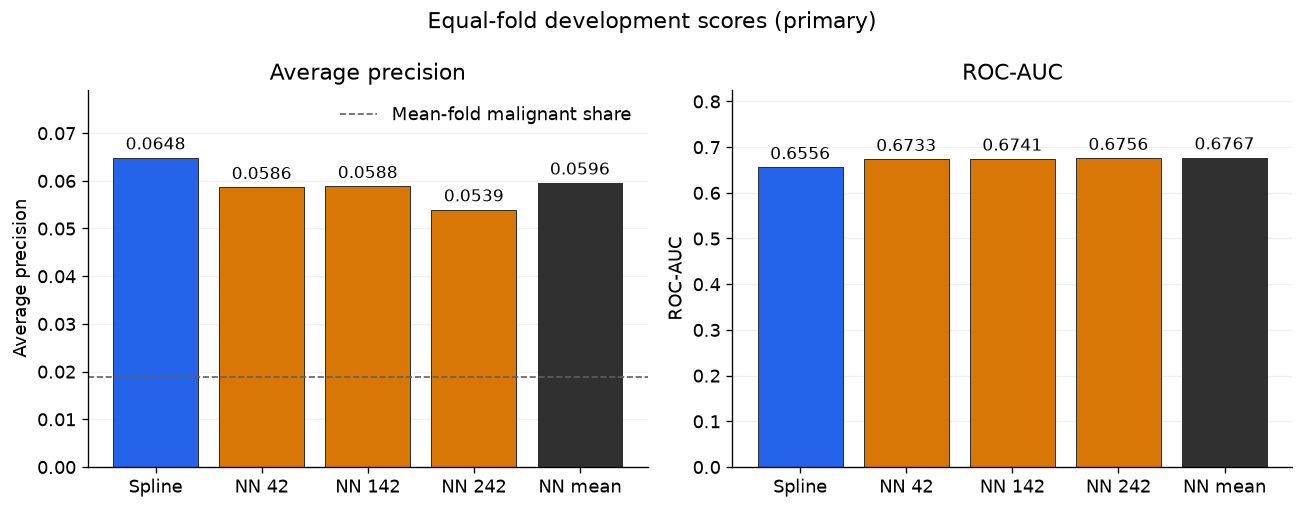

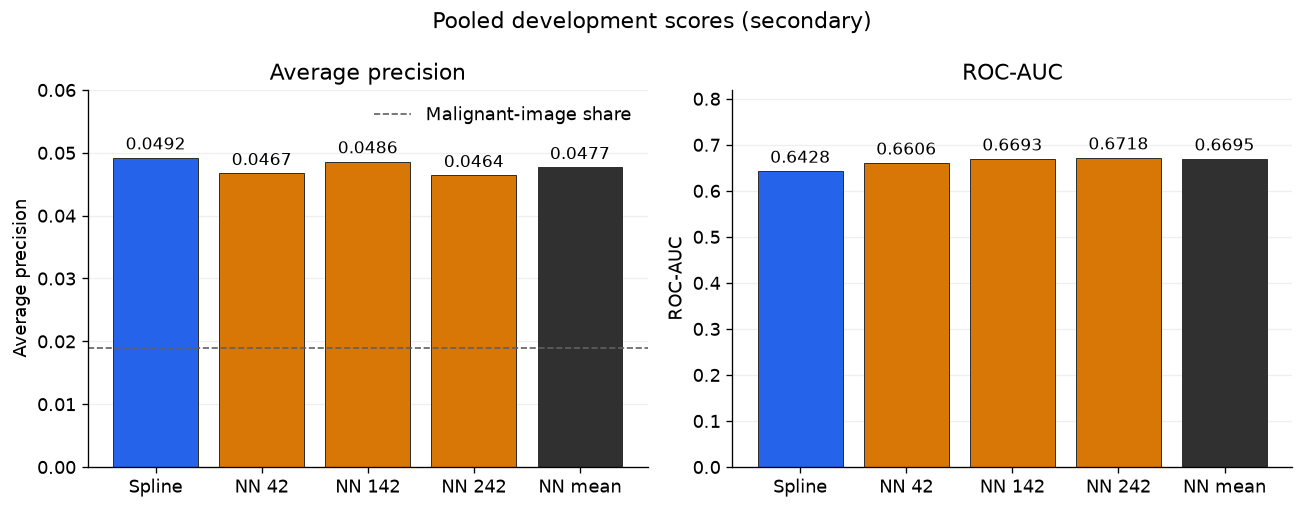

,average_precision,roc_auc
mean,0.05714,0.67432
std,0.00277,0.00120
min,0.05395,0.67325
max,0.05884,0.67562


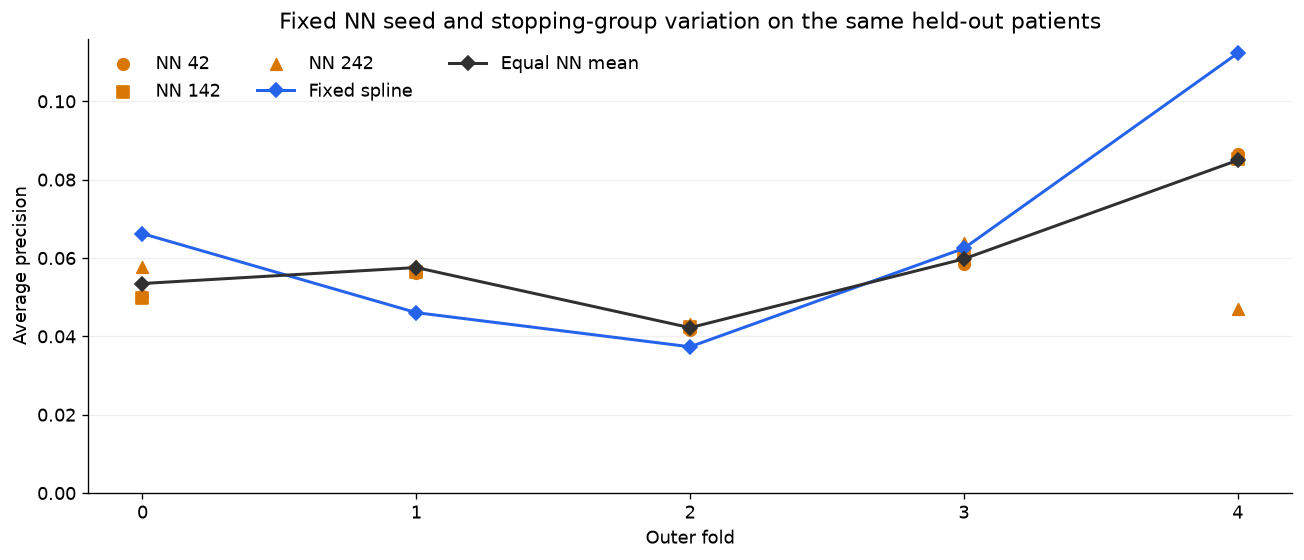

The three-run spread reflects seeds and stopping groups on the same patients; it is not a sampling confidence interval.

In [6]:
render_section(report, 'nn_metrics')

### Read the recorded training duration and histories

The epoch choices are made on training-only stopping groups. Orange marks show the individual fixed-NN runs; charcoal shows their median. Loss curves, when recorded, show fit and stopping probability error. They describe optimization, not performance on the outer patients.

,base_seed,outer_fold,training_seed,stop_fold,selected_epochs,stop_log_loss,attempted_stopping_epochs,outer_train_patients,score_patients,epoch_fit_patients,...,dropout,stage,inner_fold,provenance,stop_group,epoch_fit_images,epoch_stop_images,refit_images,refit_patients,score_images
0,42,0,42,1.0,20,0.0907,32,338.0,84,254,...,0.2,nn_outer_fixed,-1,reused_clean_fixed,1,3996,1366,5362,338,1344
1,142,0,142,2.0,18,0.0923,30,338.0,84,251,...,0.2,nn_outer_fixed,-1,reused_clean_fixed,2,4034,1328,5362,338,1344
2,242,0,242,3.0,40,0.0874,52,338.0,84,256,...,0.2,nn_outer_fixed,-1,reused_clean_fixed,3,3991,1371,5362,338,1344
3,42,1,43,2.0,59,0.0911,71,338.0,84,251,...,0.2,nn_outer_fixed,-1,reused_clean_fixed,2,4012,1328,5340,338,1366
4,142,1,143,3.0,26,0.0880,38,338.0,84,256,...,0.2,nn_outer_fixed,-1,reused_clean_fixed,3,3969,1371,5340,338,1366
5,242,1,243,4.0,12,0.0957,24,338.0,84,253,...,0.2,nn_outer_fixed,-1,reused_clean_fixed,4,4043,1297,5340,338,1366
6,42,2,44,3.0,59,0.0859,71,335.0,87,253,...,0.2,nn_outer_fixed,-1,reused_clean_fixed,3,4007,1371,5378,335,1328
7,142,2,144,4.0,12,0.0973,24,335.0,87,250,...,0.2,nn_outer_fixed,-1,reused_clean_fixed,4,4081,1297,5378,335,1328
8,242,2,244,0.0,29,0.0836,41,335.0,87,251,...,0.2,nn_outer_fixed,-1,reused_clean_fixed,0,4034,1344,5378,335,1328
9,42,3,45,4.0,11,0.0974,23,340.0,82,255,...,0.2,nn_outer_fixed,-1,reused_clean_fixed,4,4038,1297,5335,340,1371


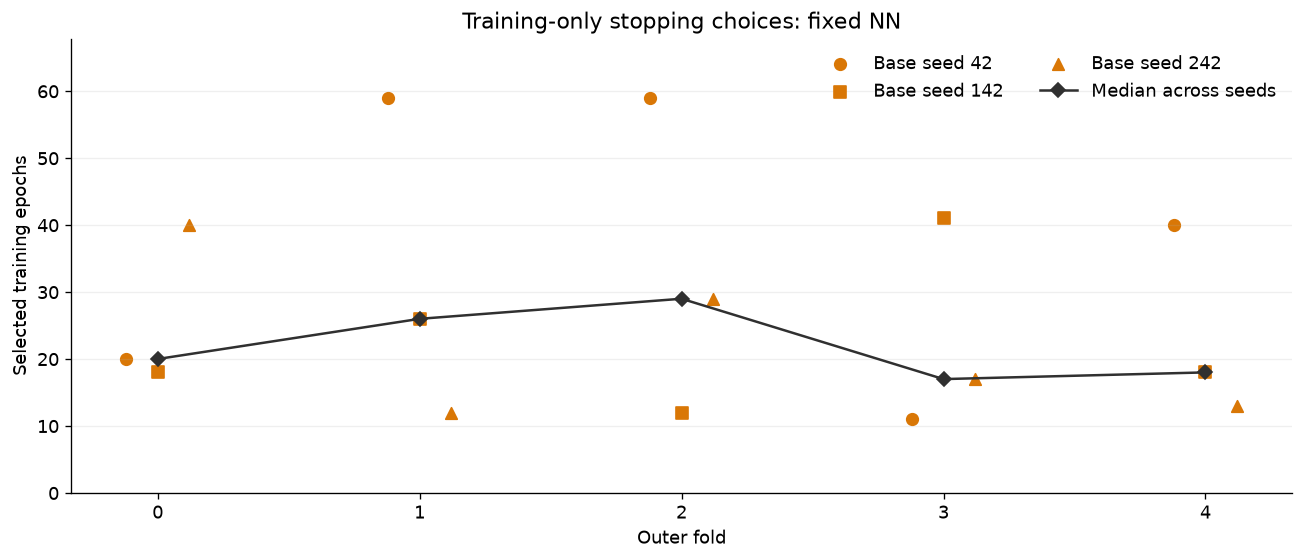

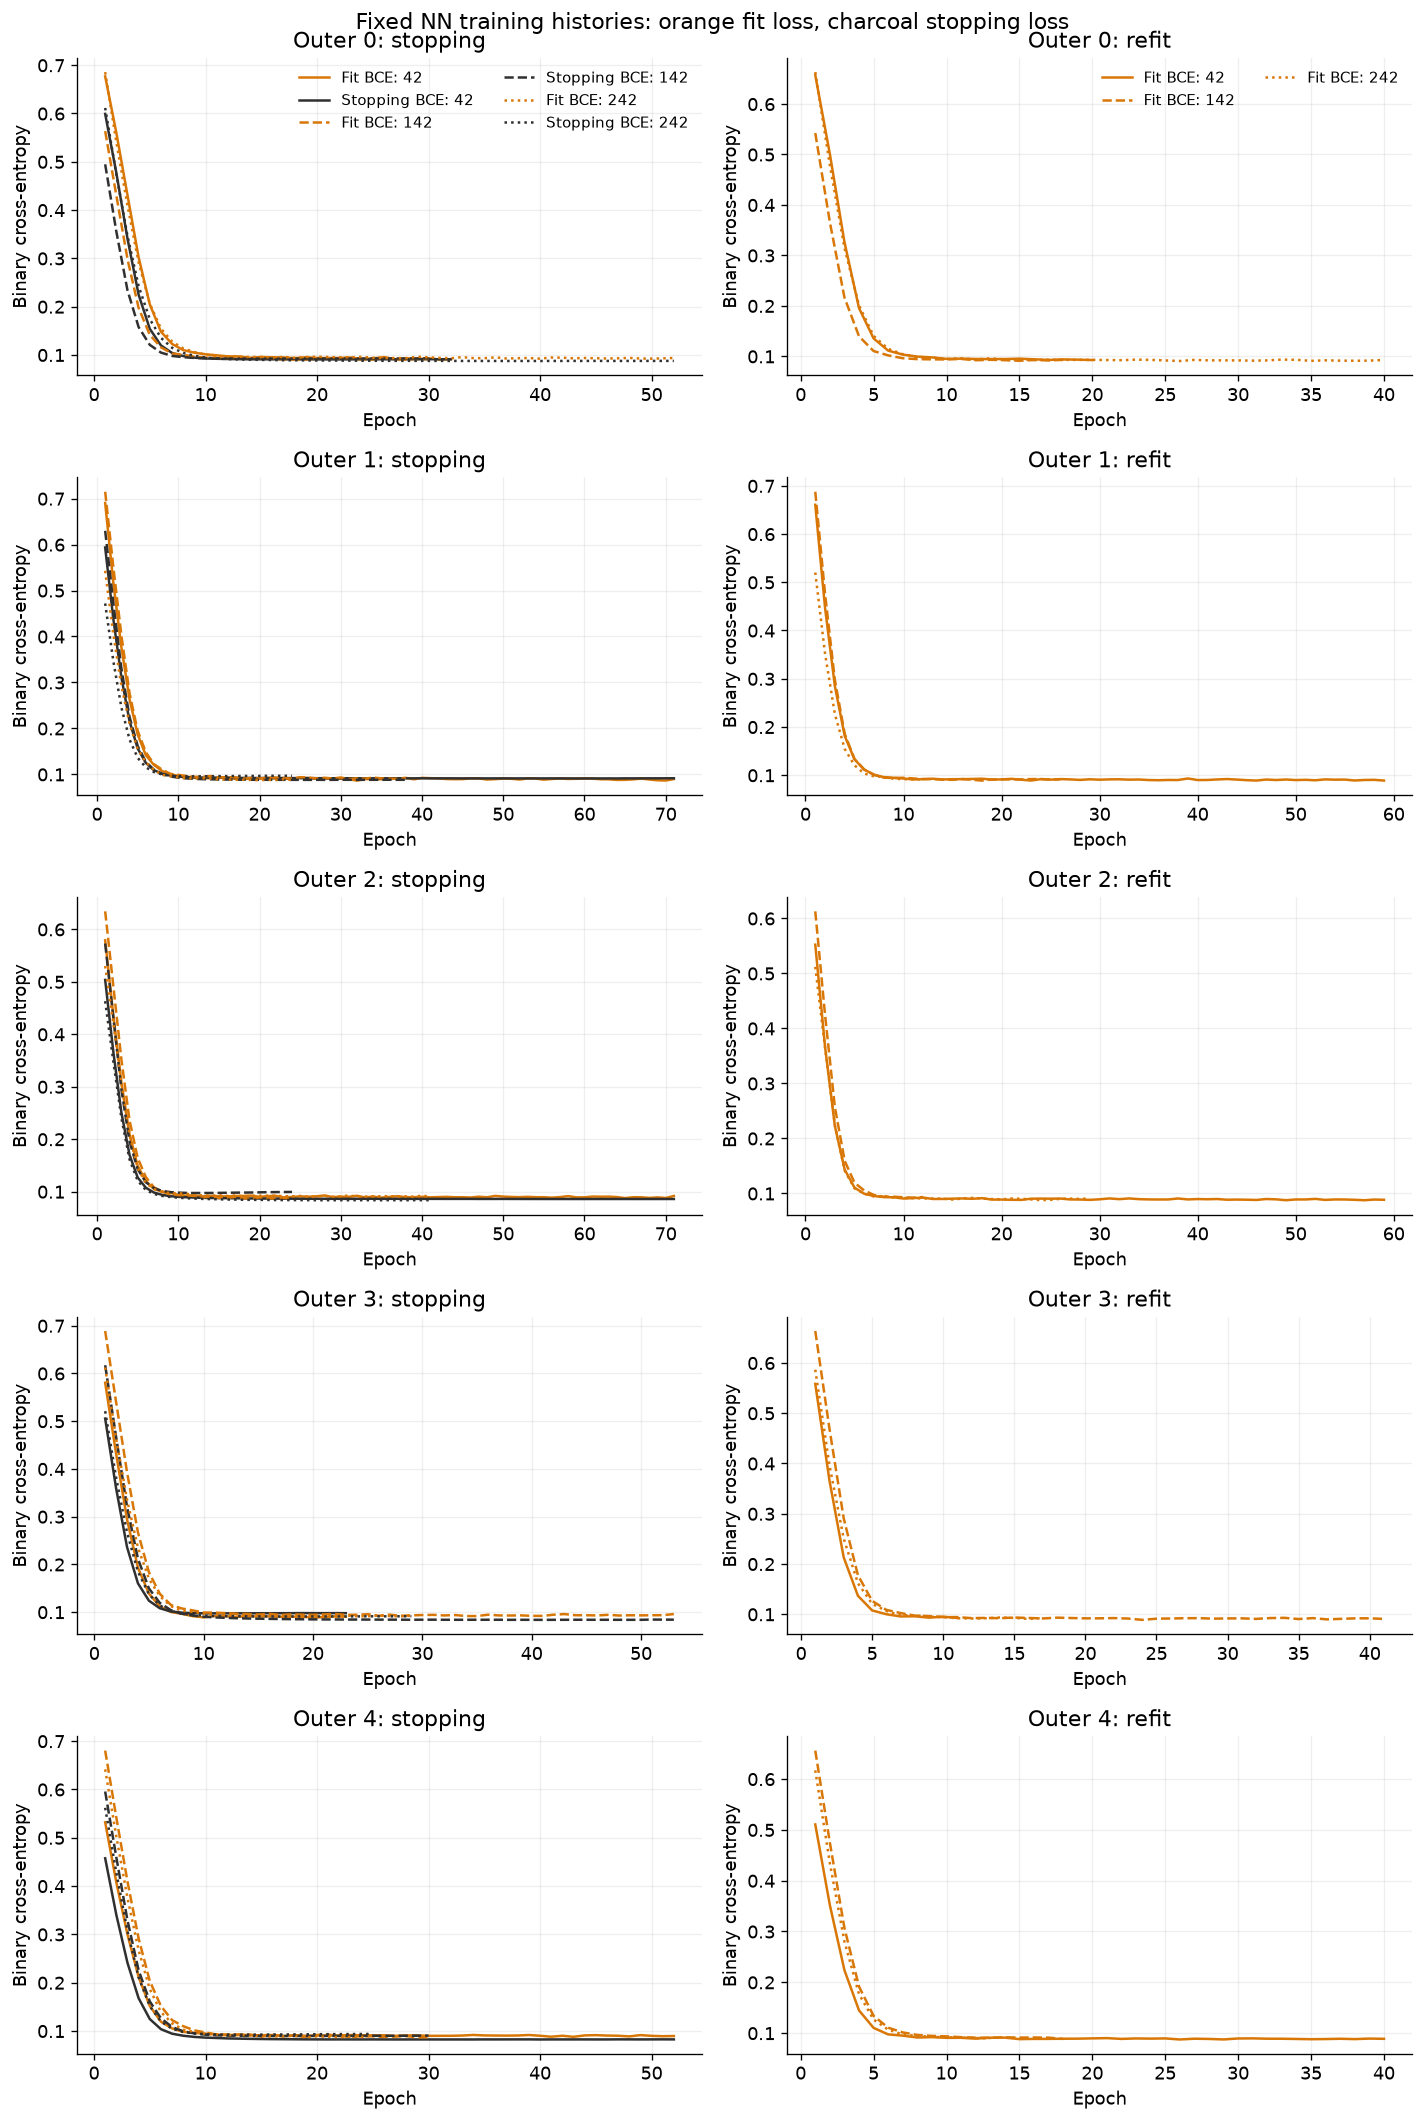

In [7]:
render_section(report, 'nn_epochs')

### 4. Read predictions and run settings

Save one row per image so later checks compare identical patients. SHA-256 fingerprints identify the exact input, prediction and executable-code bytes; markdown and saved outputs do not affect the code fingerprint. Settings record preprocessing, network design, training and package versions. Fingerprints support traceability, rather than proving correctness.

These are development outputs. Reports read hash-verified versioned predictions and settings and write presentation copies only inside the new run's `report/` directory. Historical `d1` results and the previous notebook are preserved in the archive.

In [8]:
render_section(report, 'run_settings')

,field,value
0,condition,dedup_v1
1,run_id,nn_grid36_v1
2,rows,6706
3,patients,422
4,positive_images,127
5,executed_fits,3270
6,reused_fits,690
7,test_set_loaded,False
8,final_model_fitted,False
9,config_sha256,ae719092f0e81b96aa7330d094351dcf4f73adf904b75a...


Receipt: `results/dedup_v1/metadata_nn_tuning/v1/nn_grid36_v1/receipt.json`. The report writes only under this versioned run's `report/` directory. Historical experiment files are preserved.

## Limitations

This stage compares one prescribed small architecture. Stage 07 separately searches hidden-layer size, learning rate and dropout through nested patient checks; even that bounded search cannot identify the best possible network design. Three fits check sensitivity to a few training choices. Because both the seed and stopping fold change together, their spread cannot isolate the effect of either choice.

All runs reuse the same patients. They are not three independent datasets, and the variability table is not a sampling confidence interval. This notebook does not establish calibrated probabilities or reliable performance across demographic groups; those checks belong in notebook 08.

The patient folds have guided earlier comparisons. Keeping outer patients outside fitting and epoch selection prevents direct leakage, but repeated model choices based on these folds can still make the chosen method look optimistic. Metadata also contains no lesion appearance. The reserved test is not used to evaluate these models, and performance on another hospital's patients or clinical safety is not established.


## Summary

The computed summary below reports both aggregations and the observed NN-minus-spline difference. Keep all prescribed seeds and their equal average in view: choosing the best individual run after seeing its score could favour a lucky result. Paired uncertainty and the simpler model's practical advantages remain relevant alongside the ranking scores.

Next, [07_metadata_tuning.ipynb](07_metadata_tuning.ipynb) checks model settings and [08_metadata_robustness.ipynb](08_metadata_robustness.ipynb) adds patient-based intervals, calibration and subgroup checks. Freeze the complete method before final testing.


In [9]:
render_section(report, 'nn_summary')

The fixed three-seed NN average has primary mean-fold AP **0.0596**, versus **0.0648** for the fixed spline (NN minus spline **-0.0053**). Mean-fold ROC-AUC is 0.6767 and 0.6556, respectively. Pooled secondary AP is 0.0477 versus 0.0492. These are point estimates on reused development folds. They do not establish categorical superiority or inferiority; retain paired uncertainty and simplicity in the decision. Stage 07 evaluates the separately prescribed NN tuning procedure rather than selecting the luckiest seed.